# FINAL PROJECT CODE

### Imports

In [39]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
import seaborn as sns


### Medical Insurance Dataset

In [40]:
med_ins = pd.read_csv("Medical_Insurance.csv")
med_ins.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [41]:
med_ins.isna().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

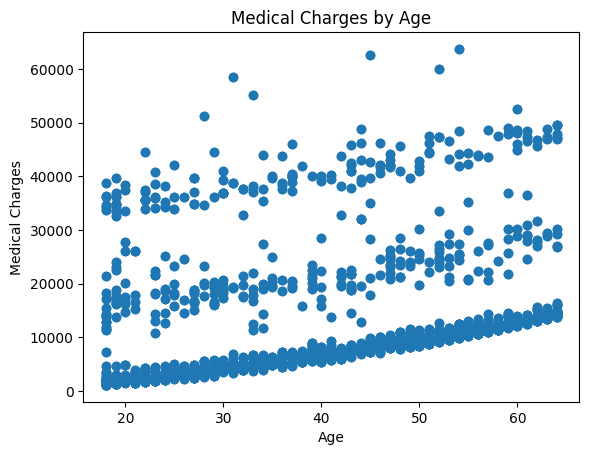

In [42]:
x_age = np.array(med_ins["age"])
y = np.array(med_ins["charges"])

plt.scatter(x_age,y)
plt.xlabel("Age")
plt.ylabel("Medical Charges")
plt.title("Medical Charges by Age")
plt.show()

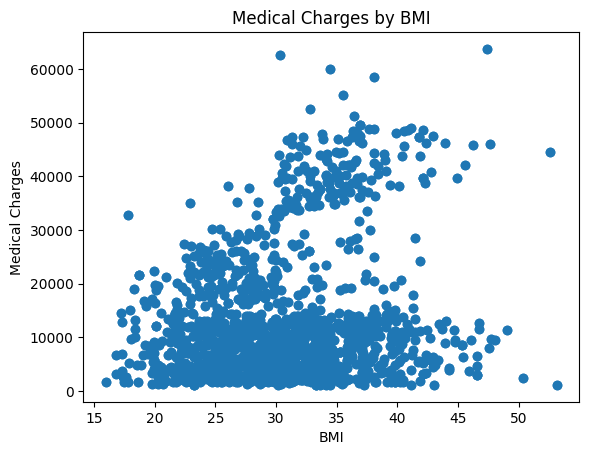

In [43]:
x_bmi = np.array(med_ins["bmi"])
y = np.array(med_ins["charges"])

plt.scatter(x_bmi,y)
plt.xlabel("BMI")
plt.ylabel("Medical Charges")
plt.title("Medical Charges by BMI")
plt.show()

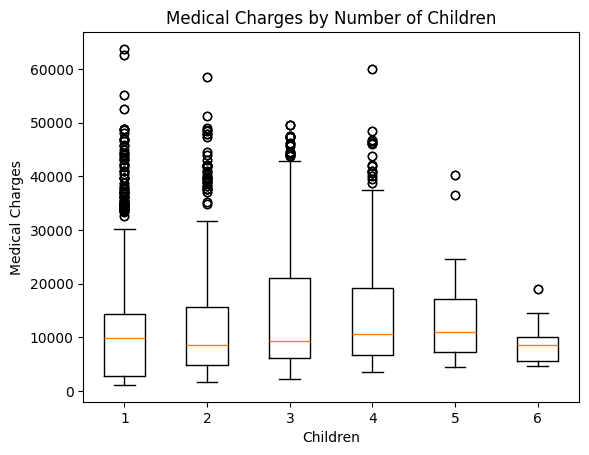

In [44]:
x_children = np.array(med_ins["children"])
y = np.array(med_ins["charges"])

data = [y[x_children == i] for i in np.unique(x_children)]

plt.boxplot(data)
plt.xlabel("Children")
plt.ylabel("Medical Charges")
plt.title("Medical Charges by Number of Children")
plt.show()

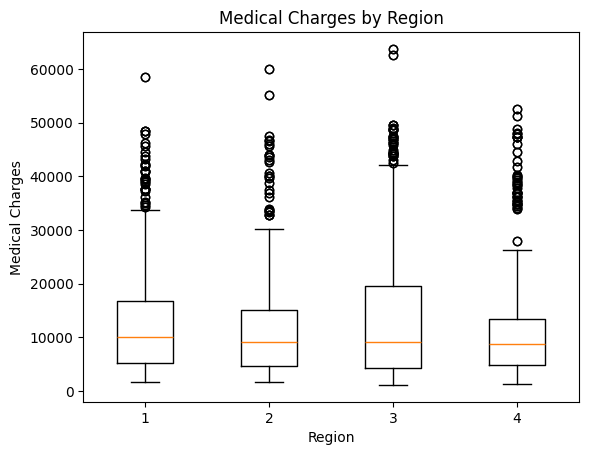

In [45]:
x_region = np.array(med_ins["region"])
y = np.array(med_ins["charges"])

data = [y[x_region == i] for i in np.unique(x_region)]

plt.boxplot(data)
plt.xlabel("Region")
plt.ylabel("Medical Charges")
plt.title("Medical Charges by Region")
plt.show()

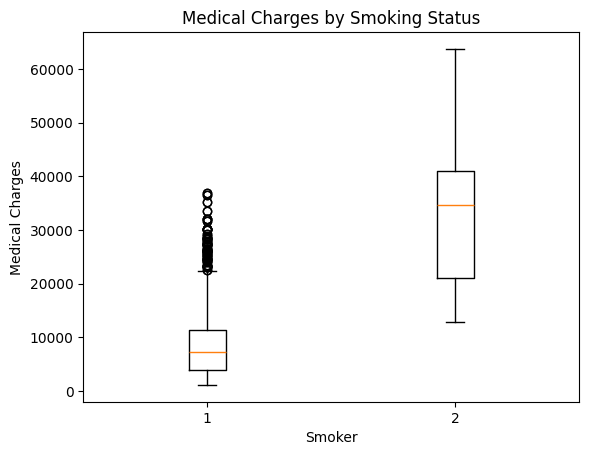

In [46]:
x_smoker = np.array(med_ins["smoker"])
y = np.array(med_ins["charges"])

data = [y[x_smoker == i] for i in np.unique(x_smoker)]

plt.boxplot(data)
plt.xlabel("Smoker")
plt.ylabel("Medical Charges")
plt.title("Medical Charges by Smoking Status")
plt.show()

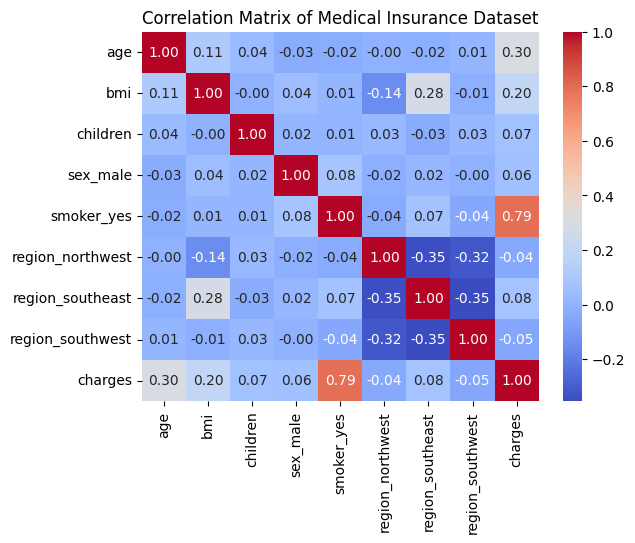

In [47]:
## Correlation Matrix, all columns

# Get dummies for categorical variables
med_inscopy = med_ins.copy()
med_ins_encoded = pd.get_dummies(med_inscopy, columns=["sex", "smoker", "region"], drop_first=True)
corr = med_ins_encoded.corr()
cols = list(corr.columns)
cols.remove("charges")
new_cols = cols + ["charges"]
corr = corr.reindex(new_cols, columns=new_cols)

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix of Medical Insurance Dataset")
plt.show()


In [48]:
X = pd.get_dummies(med_ins.drop("charges", axis=1), drop_first=True)
X=X.astype(float)
y=med_ins["charges"]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=.25,stratify=med_ins["smoker"], random_state=42)

model = LinearRegression().fit(X_train, y_train)

coef_med_ins = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})
print(coef_med_ins, "\nIntercept:", model.intercept_)


            Feature   Coefficient
0               age    252.194765
1               bmi    325.764530
2          children    509.328597
3          sex_male    121.925251
4        smoker_yes  23946.477692
5  region_northwest   -380.811519
6  region_southeast   -826.808947
7  region_southwest  -1213.952601 
Intercept: -11482.565672781371


In [49]:
X_train_sm = sm.add_constant(X_train)

model_sm = sm.OLS(y_train, X_train_sm).fit()
model_sm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.759
Model:                            OLS   Adj. R-squared:                  0.758
Method:                 Least Squares   F-statistic:                     814.3
Date:                Tue, 05 May 2026   Prob (F-statistic):               0.00
Time:                        14:21:44   Log-Likelihood:                -21028.
No. Observations:                2079   AIC:                         4.207e+04
Df Residuals:                    2070   BIC:                         4.212e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const            -1.148e+04    788.817    -14.557      0.000    -1.3e+04   -9935.609
age                252.1948      9.388     26.864      0.000     233.784     270.605
bmi                325.7645     22.858     14.251      0.000     280.937     370.593
children           509.3286    109.175      4.665      0.000     295.225     723.432
sex_male           121.9253    264.794      0.460      0.645    -397.365     641.216
smoker_yes        2.395e+04    328.961     72.794      0.000    2.33e+04    2.46e+04
region_northwest  -380.8115    378.583     -1.006      0.315   -1123.254     361.631
region_southeast  -826.8089    379.719     -2.177      0.030   -1571.480     -82.138
region_southwest -1213.9526    376.495     -3.224      0.001   -1952.301    -475.604
==============================================================================
Omnibus:                      456.505   Durbin-Watson:                   1.975
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1121.674
Skew:                           1.189   Prob(JB):                    2.70e-244
Kurtosis:                       5.700   Cond. No.                         313.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [50]:
X = X.drop(columns=["sex_male"])

X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=42)
X_train_sm = sm.add_constant(X_train)
model_sm = sm.OLS(y_train, X_train_sm).fit()

model_sm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.755
Model:                            OLS   Adj. R-squared:                  0.754
Method:                 Least Squares   F-statistic:                     910.1
Date:                Tue, 05 May 2026   Prob (F-statistic):               0.00
Time:                        14:21:44   Log-Likelihood:                -21014.
No. Observations:                2079   AIC:                         4.204e+04
Df Residuals:                    2071   BIC:                         4.209e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const            -1.141e+04    771.113    -14.802      0.000   -1.29e+04   -9901.936
age                254.0241      9.448     26.886      0.000     235.495     272.553
bmi                322.4019     22.459     14.355      0.000     278.358     366.446
children           507.5904    107.835      4.707      0.000     296.114     719.067
smoker_yes        2.376e+04    323.654     73.417      0.000    2.31e+04    2.44e+04
region_northwest  -523.8450    375.431     -1.395      0.163   -1260.107     212.417
region_southeast -1087.2885    378.379     -2.874      0.004   -1829.332    -345.245
region_southwest -1001.9566    376.281     -2.663      0.008   -1739.885    -264.028
==============================================================================
Omnibus:                      456.074   Durbin-Watson:                   1.971
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1106.964
Skew:                           1.194   Prob(JB):                    4.23e-241
Kurtosis:                       5.661   Cond. No.                         309.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [51]:
X = X.drop(columns=["region_northwest","region_southeast","region_southwest"])

X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=42)
X_train_sm = sm.add_constant(X_train)
model_sm = sm.OLS(y_train, X_train_sm).fit()

model_sm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.753
Model:                            OLS   Adj. R-squared:                  0.753
Method:                 Least Squares   F-statistic:                     1584.
Date:                Tue, 05 May 2026   Prob (F-statistic):               0.00
Time:                        14:21:44   Log-Likelihood:                -21019.
No. Observations:                2079   AIC:                         4.205e+04
Df Residuals:                    2074   BIC:                         4.208e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1.161e+04    743.585    -15.613      0.000   -1.31e+04   -1.02e+04
age          255.1406      9.454     26.986      0.000     236.599     273.682
bmi          305.7552     21.544     14.192      0.000     263.504     348.006
children     505.5589    107.946      4.683      0.000     293.865     717.253
smoker_yes  2.374e+04    322.915     73.527      0.000    2.31e+04    2.44e+04
==============================================================================
Omnibus:                      458.186   Durbin-Watson:                   1.969
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1113.251
Skew:                           1.198   Prob(JB):                    1.82e-242
Kurtosis:                       5.666   Cond. No.                         293.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

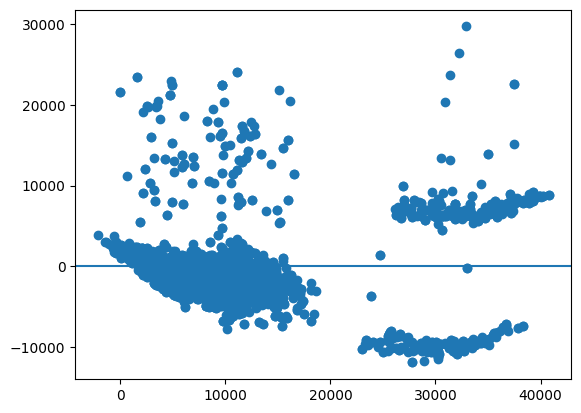

In [52]:
plt.scatter(model_sm.fittedvalues, model_sm.resid)
plt.axhline(0)

We can see distinct clusters and patterns arising here which leads us to create interaction terms. 

In [53]:
y=np.log(med_ins["charges"])
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=42)
X_train_sm = sm.add_constant(X_train)
model_sm = sm.OLS(y_train, X_train_sm).fit()

model_sm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.768
Model:                            OLS   Adj. R-squared:                  0.768
Method:                 Least Squares   F-statistic:                     1719.
Date:                Tue, 05 May 2026   Prob (F-statistic):               0.00
Time:                        14:21:44   Log-Likelihood:                -1229.0
No. Observations:                2079   AIC:                             2468.
Df Residuals:                    2074   BIC:                             2496.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.0063      0.055    128.317      0.000       6.899       7.113
age            0.0349      0.001     50.201      0.000       0.033       0.036
bmi            0.0098      0.002      6.198      0.000       0.007       0.013
children       0.0984      0.008     12.414      0.000       0.083       0.114
smoker_yes     1.5458      0.024     65.193      0.000       1.499       1.592
==============================================================================
Omnibus:                      697.934   Durbin-Watson:                   1.968
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             2602.496
Skew:                           1.627   Prob(JB):                         0.00
Kurtosis:                       7.410   Cond. No.                         293.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

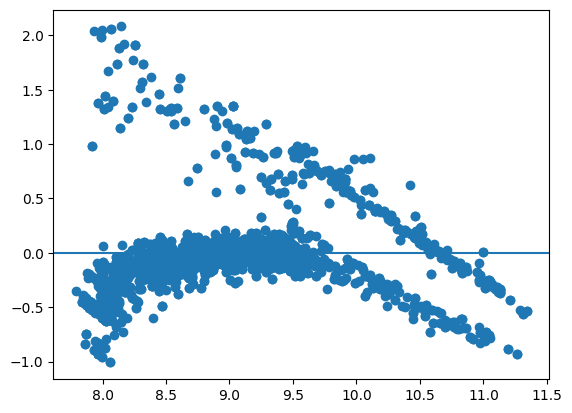

In [54]:
plt.scatter(model_sm.fittedvalues, model_sm.resid)
plt.axhline(0)

In [55]:
X["bmi_smoker"] = X["bmi"]*X["smoker_yes"]
X["age_smoker"] = X["age"]*X["smoker_yes"]

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

model_sm = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(model_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.826
Model:                            OLS   Adj. R-squared:                  0.826
Method:                 Least Squares   F-statistic:                     1643.
Date:                Tue, 05 May 2026   Prob (F-statistic):               0.00
Time:                        14:21:45   Log-Likelihood:                -929.06
No. Observations:                2079   AIC:                             1872.
Df Residuals:                    2072   BIC:                             1912.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.0848      0.053    134.227      0.0

In [56]:
X = X.drop(columns=["age_smoker"])

X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=42)
X_train_sm = sm.add_constant(X_train)
model_sm = sm.OLS(y_train, X_train_sm).fit()

model_sm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.783
Model:                            OLS   Adj. R-squared:                  0.783
Method:                 Least Squares   F-statistic:                     1500.
Date:                Tue, 05 May 2026   Prob (F-statistic):               0.00
Time:                        14:21:45   Log-Likelihood:                -1158.4
No. Observations:                2079   AIC:                             2329.
Df Residuals:                    2073   BIC:                             2363.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.2959      0.058    125.798      0.000       7.182       7.410
age            0.0351      0.001     52.310      0.000       0.034       0.036
bmi         1.116e-06      0.002      0.001      0.999      -0.003       0.003
children       0.0982      0.008     12.811      0.000       0.083       0.113
smoker_yes     0.1874      0.115      1.631      0.103      -0.038       0.413
bmi_smoker     0.0443      0.004     12.064      0.000       0.037       0.051
==============================================================================
Omnibus:                      777.766   Durbin-Watson:                   1.969
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             3310.219
Skew:                           1.778   Prob(JB):                         0.00
Kurtosis:                       8.056   Cond. No.                         660.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [57]:
X = X.drop(columns=["bmi"])

X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=42)
X_train_sm = sm.add_constant(X_train)
model_sm = sm.OLS(y_train, X_train_sm).fit()

model_sm.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.783
Model:                            OLS   Adj. R-squared:                  0.783
Method:                 Least Squares   F-statistic:                     1876.
Date:                Tue, 05 May 2026   Prob (F-statistic):               0.00
Time:                        14:21:45   Log-Likelihood:                -1158.4
No. Observations:                2079   AIC:                             2327.
Df Residuals:                    2074   BIC:                             2355.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.2960      0.030    246.996      0.000       7.238       7.354
age            0.0351      0.001     52.704      0.000       0.034       0.036
children       0.0982      0.008     12.814      0.000       0.083       0.113
smoker_yes     0.1874      0.102      1.835      0.067      -0.013       0.388
bmi_smoker     0.0443      0.003     13.664      0.000       0.038       0.051
==============================================================================
Omnibus:                      777.766   Durbin-Watson:                   1.969
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             3310.212
Skew:                           1.778   Prob(JB):                         0.00
Kurtosis:                       8.056   Cond. No.                         465.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

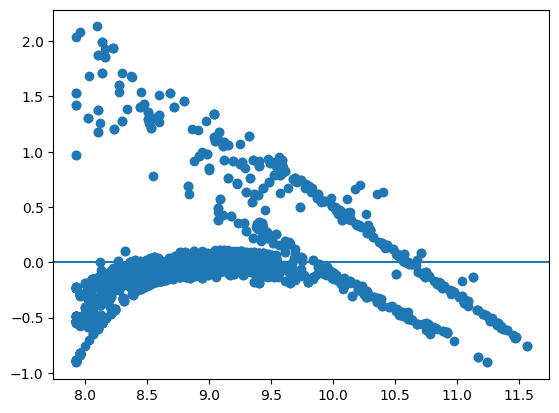

In [58]:
plt.scatter(model_sm.fittedvalues, model_sm.resid)
plt.axhline(0)

In [59]:
y=np.log(med_ins["charges"])
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=42)
X_train_sm = sm.add_constant(X_train)
model_sm = sm.OLS(y_train, X_train_sm).fit()

model_sm.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                charges   R-squared:                       0.783
Model:                            OLS   Adj. R-squared:                  0.783
Method:                 Least Squares   F-statistic:                     1876.
Date:                Tue, 05 May 2026   Prob (F-statistic):               0.00
Time:                        14:21:45   Log-Likelihood:                -1158.4
No. Observations:                2079   AIC:                             2327.
Df Residuals:                    2074   BIC:                             2355.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.2960      0.030    246.996      0.000       7.238       7.354
age            0.0351      0.001     52.704      0.000       0.034       0.036
children       0.0982      0.008     12.814      0.000       0.083       0.113
smoker_yes     0.1874      0.102      1.835      0.067      -0.013       0.388
bmi_smoker     0.0443      0.003     13.664      0.000       0.038       0.051
==============================================================================
Omnibus:                      777.766   Durbin-Watson:                   1.969
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             3310.212
Skew:                           1.778   Prob(JB):                         0.00
Kurtosis:                       8.056   Cond. No.                         465.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### Linear Regression: Non-Smoker vs Smoker

#### Non-Smoker

In [60]:
med_ins_no_smoker = med_ins[med_ins["smoker"] == "no"].copy()
X_ns = pd.get_dummies(med_ins_no_smoker.drop("charges", axis=1), drop_first=True).astype(float)
y_ns = med_ins_no_smoker["charges"]
X_train, X_test, y_train, y_test = train_test_split(X_ns, y_ns, test_size=.25, stratify=med_ins_no_smoker["smoker"], random_state=42)

#Calculte weights for WLS in-sample
print("\n============OLS No Smoker In-Sample Results:============")
X_ns = sm.add_constant(X_ns)
results_wls_ns = sm.OLS(y_ns, X_ns).fit()
print(results_wls_ns.summary())

#Calculate weights for WLS on training data
print("\n============OLS No Smoker Train Results:============")
X_train = sm.add_constant(X_train)
results_wls_ns_train = sm.OLS(y_train, X_train).fit()
print(results_wls_ns_train.summary())

#Predict on test data
X_test = sm.add_constant(X_test)
results_wls_ns_test = results_wls_ns_train.predict(X_test)
print("\n============OLS No Smoker Test Results:============")
rmse_wls = np.sqrt(np.mean((y_test - results_wls_ns_test) ** 2))
print(f"WLS Test RMSE: {rmse_wls}")
rsquared_wls = 1 - np.sum((y_test - results_wls_ns_test) ** 2) / np.sum((y_test - np.mean(y_test)) ** 2)
print(f"WLS Test R-squared: {rsquared_wls}")
print(f"WLS Test Coefficients:\n{results_wls_ns_train.params}")


============OLS No Smoker In-Sample Results:============
                            OLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.410
Model:                            OLS   Adj. R-squared:                  0.408
Method:                 Least Squares   F-statistic:                     218.3
Date:                Tue, 05 May 2026   Prob (F-statistic):          1.37e-246
Time:                        14:21:45   Log-Likelihood:                -21764.
No. Observations:                2208   AIC:                         4.354e+04
Df Residuals:                    2200   BIC:                         4.359e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------

#### Smoker

In [61]:
med_ins_no_smoker = med_ins[med_ins["smoker"] == "yes"].copy()
X_ns = pd.get_dummies(med_ins_no_smoker.drop("charges", axis=1), drop_first=True).astype(float)
y_ns = med_ins_no_smoker["charges"]
X_train, X_test, y_train, y_test = train_test_split(X_ns, y_ns, test_size=.25, stratify=med_ins_no_smoker["smoker"], random_state=42)

#Calculte weights for WLS in-sample
print("\n============OLS No Smoker In-Sample Results:============")
X_ns = sm.add_constant(X_ns)
results_wls_ns = sm.OLS(y_ns, X_ns).fit()
print(results_wls_ns.summary())

#Calculate weights for WLS on training data
print("\n============OLS No Smoker Train Results:============")
X_train = sm.add_constant(X_train)
results_wls_ns_train = sm.OLS(y_train, X_train).fit()
print(results_wls_ns_train.summary())

#Predict on test data
X_test = sm.add_constant(X_test)
results_wls_ns_test = results_wls_ns_train.predict(X_test)
print("\n============OLS No Smoker Test Results:============")
rmse_wls = np.sqrt(np.mean((y_test - results_wls_ns_test) ** 2))
print(f"WLS Test RMSE: {rmse_wls}")
rsquared_wls = 1 - np.sum((y_test - results_wls_ns_test) ** 2) / np.sum((y_test - np.mean(y_test)) ** 2)
print(f"WLS Test R-squared: {rsquared_wls}")
print(f"WLS Test Coefficients:\n{results_wls_ns_train.params}")


============OLS No Smoker In-Sample Results:============
                            OLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.761
Model:                            OLS   Adj. R-squared:                  0.758
Method:                 Least Squares   F-statistic:                     253.0
Date:                Tue, 05 May 2026   Prob (F-statistic):          2.80e-168
Time:                        14:21:45   Log-Likelihood:                -5670.5
No. Observations:                 564   AIC:                         1.136e+04
Df Residuals:                     556   BIC:                         1.139e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------

### Weighted Regression (75-25 split)

In [62]:
X = pd.get_dummies(med_ins.drop("charges", axis=1), drop_first=True).astype(float)
y=med_ins["charges"]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=.25,stratify=med_ins["smoker"], random_state=42)

#### In-Sample

In [63]:
#Calculate weights for WLS
errors = y - y.mean()
weights = 1 / (np.var(errors))
X = sm.add_constant(X)
results_wls = sm.WLS(y, X, weights=weights).fit()
print(results_wls.summary())

                            WLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.751
Model:                            WLS   Adj. R-squared:                  0.750
Method:                 Least Squares   F-statistic:                     1041.
Date:                Tue, 05 May 2026   Prob (F-statistic):               0.00
Time:                        14:21:45   Log-Likelihood:                -28078.
No. Observations:                2772   AIC:                         5.617e+04
Df Residuals:                    2763   BIC:                         5.623e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const            -1.164e+04    686.885  

Text(0.5, 1.0, 'WLS Residuals vs Fitted Values before backwards selection')

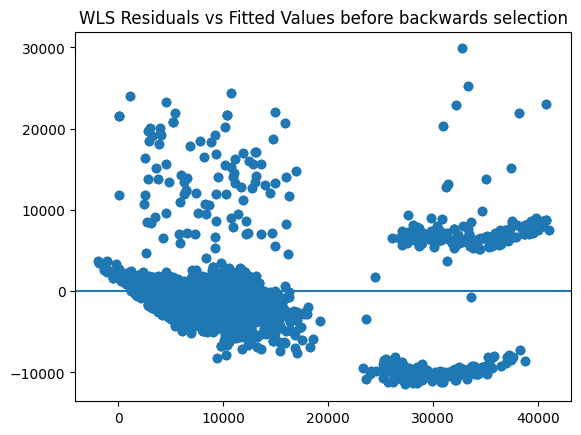

In [64]:
plt.scatter(results_wls.fittedvalues, results_wls.resid)
plt.axhline(0)
plt.title("WLS Residuals vs Fitted Values before backwards selection")

In [65]:
##### Remove high p-value vars
X = X.drop(["sex_male", "region_northwest"], axis = 1)
X = sm.add_constant(X)
results_wls = sm.WLS(y, X, weights=weights).fit()
print(results_wls.summary())

                            WLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.751
Model:                            WLS   Adj. R-squared:                  0.750
Method:                 Least Squares   F-statistic:                     1389.
Date:                Tue, 05 May 2026   Prob (F-statistic):               0.00
Time:                        14:21:46   Log-Likelihood:                -28078.
No. Observations:                2772   AIC:                         5.617e+04
Df Residuals:                    2765   BIC:                         5.621e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const            -1.183e+04    658.933  

Text(0.5, 1.0, 'WLS Residuals vs Fitted Values after backwards selection')

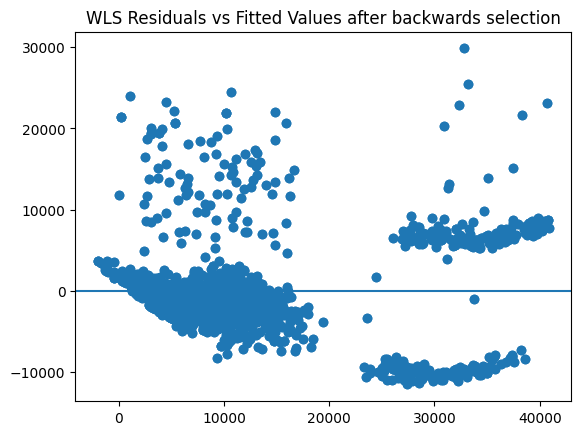

In [66]:
plt.scatter(results_wls.fittedvalues, results_wls.resid)
plt.axhline(0)
plt.title("WLS Residuals vs Fitted Values after backwards selection")

#### Out of Sample

In [67]:
#Calculate weights for WLS on training data
errors = y_train - y_train.mean()
weights = 1 / (np.var(errors))
X_train = sm.add_constant(X_train)
results_wls_train = sm.WLS(y_train, X_train, weights=weights).fit()
print(results_wls_train.summary())




                            WLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.759
Model:                            WLS   Adj. R-squared:                  0.758
Method:                 Least Squares   F-statistic:                     814.3
Date:                Tue, 05 May 2026   Prob (F-statistic):               0.00
Time:                        14:21:46   Log-Likelihood:                -21028.
No. Observations:                2079   AIC:                         4.207e+04
Df Residuals:                    2070   BIC:                         4.212e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const            -1.148e+04    788.817  

In [68]:
#Predict on test data
X_test = sm.add_constant(X_test)
results_wls_test = results_wls_train.predict(X_test)

#Calculate metrics from WLS train for WLS test
print("\n============WLS Test Results:============")
rmse_wls = np.sqrt(np.mean((y_test - results_wls_test) ** 2))
print(f"WLS Test RMSE: {rmse_wls}")
rsquared_wls = 1 - np.sum((y_test - results_wls_test) ** 2) / np.sum((y_test - np.mean(y_test)) ** 2)
print(f"WLS Test R-squared: {rsquared_wls}")
print(f"WLS Test Coefficients:\n{results_wls_train.params}")


============WLS Test Results:============
WLS Test RMSE: 6331.919668192115
WLS Test R-squared: 0.7257879433388721
WLS Test Coefficients:
const              -11482.565673
age                   252.194765
bmi                   325.764530
children              509.328597
sex_male              121.925251
smoker_yes          23946.477692
region_northwest     -380.811519
region_southeast     -826.808947
region_southwest    -1213.952601
dtype: float64


In [69]:
##remove high p-value variables
X_train = X_train.drop(["sex_male", "region_northwest"], axis = 1)
X_train = sm.add_constant(X_train)
results_wls_train = sm.WLS(y_train, X_train, weights=weights).fit()
print(results_wls_train.summary())

                            WLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.759
Model:                            WLS   Adj. R-squared:                  0.758
Method:                 Least Squares   F-statistic:                     1086.
Date:                Tue, 05 May 2026   Prob (F-statistic):               0.00
Time:                        14:21:46   Log-Likelihood:                -21028.
No. Observations:                2079   AIC:                         4.207e+04
Df Residuals:                    2072   BIC:                         4.211e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const            -1.162e+04    753.526  

In [70]:
#Predict on test data
X_test = X_test.drop(["sex_male", "region_northwest"], axis = 1)
X_test = sm.add_constant(X_test)
results_wls_test = results_wls_train.predict(X_test)

#Calculate metrics from WLS train for WLS test
print("\n============WLS Test Results:============")
rmse_wls = np.sqrt(np.mean((y_test - results_wls_test) ** 2))
print(f"WLS Test RMSE: {rmse_wls}")
rsquared_wls = 1 - np.sum((y_test - results_wls_test) ** 2) / np.sum((y_test - np.mean(y_test)) ** 2)
print(f"WLS Test R-squared: {rsquared_wls}")
print(f"WLS Test Coefficients:\n{results_wls_train.params}")


============WLS Test Results:============
WLS Test RMSE: 6328.370302165709
WLS Test R-squared: 0.7260952770457167
WLS Test Coefficients:
const              -11622.886978
age                   252.076057
bmi                   326.432708
children              504.802216
smoker_yes          23971.222595
region_southeast     -643.156221
region_southwest    -1025.004979
dtype: float64


### Weighted: Non-Smoker vs Smoker 

#### Non-Smokers Weighted Regression

In [71]:
med_ins_no_smoker = med_ins[med_ins["smoker"] == "no"].copy()
X_ns = pd.get_dummies(med_ins_no_smoker.drop("charges", axis=1), drop_first=True).astype(float)
y_ns = med_ins_no_smoker["charges"]
X_train, X_test, y_train, y_test = train_test_split(X_ns, y_ns, test_size=.25, stratify=med_ins_no_smoker["smoker"], random_state=42)

#Calculte weights for WLS in-sample
print("\n============WLS No Smoker In-Sample Results:============")
errors = y_ns - y_ns.mean()
weights = 1 / (np.var(errors))
X_ns = sm.add_constant(X_ns)
results_wls_ns = sm.WLS(y_ns, X_ns, weights=weights).fit()
print(results_wls_ns.summary())

#Calculate weights for WLS on training data
print("\n============WLS No Smoker Train Results:============")
errors = y_train - y_train.mean()
weights = 1 / (np.var(errors))
X_train = sm.add_constant(X_train)
results_wls_ns_train = sm.WLS(y_train, X_train, weights=weights).fit()
print(results_wls_ns_train.summary())

#Predict on test data
X_test = sm.add_constant(X_test)
results_wls_ns_test = results_wls_ns_train.predict(X_test)
print("\n============WLS No Smoker Test Results:============")
rmse_wls = np.sqrt(np.mean((y_test - results_wls_ns_test) ** 2))
print(f"WLS Test RMSE: {rmse_wls}")
rsquared_wls = 1 - np.sum((y_test - results_wls_ns_test) ** 2) / np.sum((y_test - np.mean(y_test)) ** 2)
print(f"WLS Test R-squared: {rsquared_wls}")
print(f"WLS Test Coefficients:\n{results_wls_ns_train.params}")


============WLS No Smoker In-Sample Results:============
                            WLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.410
Model:                            WLS   Adj. R-squared:                  0.408
Method:                 Least Squares   F-statistic:                     218.3
Date:                Tue, 05 May 2026   Prob (F-statistic):          1.37e-246
Time:                        14:21:46   Log-Likelihood:                -21764.
No. Observations:                2208   AIC:                         4.354e+04
Df Residuals:                    2200   BIC:                         4.359e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------

Text(0.5, 1.0, 'WLS No Smoker Residuals vs Fitted Values')

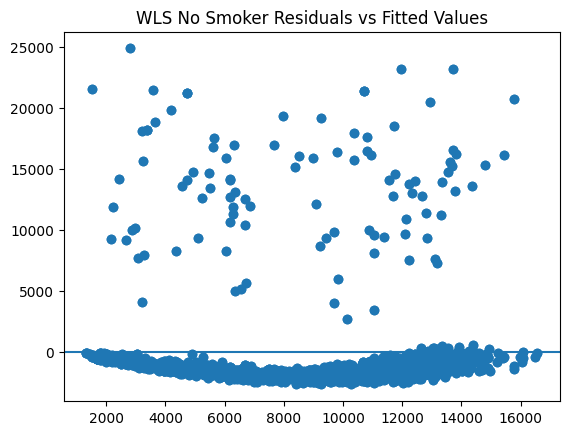

In [72]:
plt.scatter(results_wls_ns.fittedvalues, results_wls_ns.resid)
plt.axhline(0)
plt.title("WLS No Smoker Residuals vs Fitted Values")

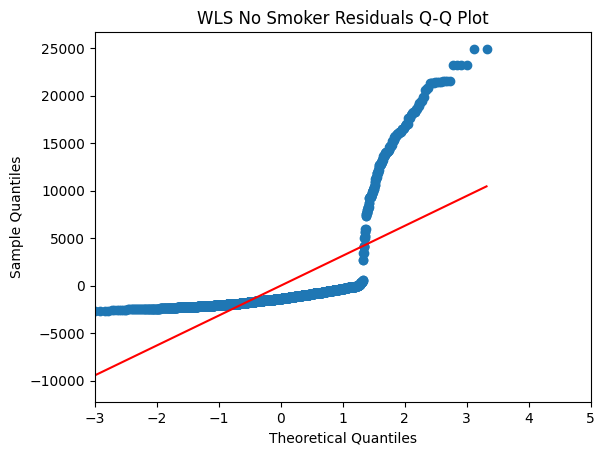

In [ ]:
sm.qqplot(results_wls_ns.resid, line='s')
plt.title("WLS Non-Smoker Residuals Q-Q Plot")

#### Smokers Weighted Regression

In [74]:
med_ins_smoker = med_ins[med_ins["smoker"] == "yes"].copy()
X_s = pd.get_dummies(med_ins_smoker.drop("charges", axis=1), drop_first=True).astype(float)
y_s = med_ins_smoker["charges"]
X_train, X_test, y_train, y_test = train_test_split(X_s, y_s, test_size=.25, stratify=med_ins_smoker["smoker"], random_state=42)

#Calculte weights for WLS in-sample
print("\n============WLS Smoker In-Sample Results:============")
errors = y_s - y_s.mean()
weights = 1 / (np.var(errors))
X_s = sm.add_constant(X_s)
results_wls_s = sm.WLS(y_s, X_s, weights=weights).fit()
print(results_wls_s.summary())

#Calculate weights for WLS on training data
print("\n============WLS Smoker Train Results:============")
errors = y_train - y_train.mean()
weights = 1 / (np.var(errors))
X_train = sm.add_constant(X_train)
results_wls_s_train = sm.WLS(y_train, X_train, weights=weights).fit()
print(results_wls_s_train.summary())

#Predict on test data
X_test = sm.add_constant(X_test)
results_wls_s_test = results_wls_s_train.predict(X_test)
print("\n============WLS Smoker Test Results:============")
rmse_wls = np.sqrt(np.mean((y_test - results_wls_s_test) ** 2))
print(f"WLS Test RMSE: {rmse_wls}")
rsquared_wls = 1 - np.sum((y_test - results_wls_s_test) ** 2) / np.sum((y_test - np.mean(y_test)) ** 2)
print(f"WLS Test R-squared: {rsquared_wls}")
print(f"WLS Test Coefficients:\n{results_wls_s_train.params}")


============WLS Smoker In-Sample Results:============
                            WLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.761
Model:                            WLS   Adj. R-squared:                  0.758
Method:                 Least Squares   F-statistic:                     253.0
Date:                Tue, 05 May 2026   Prob (F-statistic):          2.80e-168
Time:                        14:21:47   Log-Likelihood:                -5670.5
No. Observations:                 564   AIC:                         1.136e+04
Df Residuals:                     556   BIC:                         1.139e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------

Text(0.5, 1.0, 'WLS Smoker Residuals vs Fitted Values')

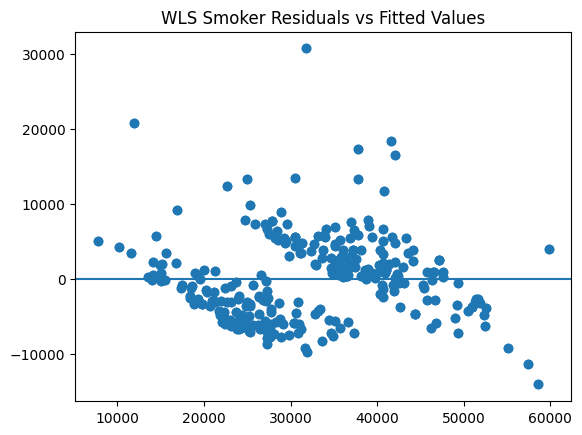

In [75]:
plt.scatter(results_wls_s.fittedvalues, results_wls_s.resid)
plt.axhline(0)
plt.title("WLS Smoker Residuals vs Fitted Values")

Text(0.5, 1.0, 'WLS Smoker Residuals Q-Q Plot')

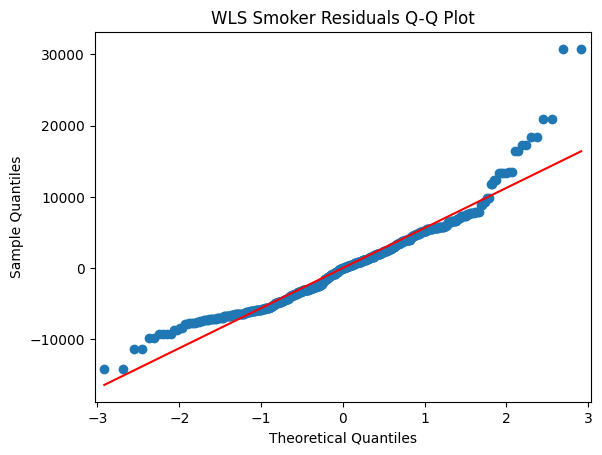

In [77]:
sm.qqplot(results_wls_s.resid, line='s')
plt.title("WLS Smoker Residuals Q-Q Plot")

### Conclusions

* The smoker variable seems to play the largest role in a person's medical charges, having a near 0.8 correlation and showing
* Weighted regression performed much worse when the data was only involved non-smokers while performing far better on data for smokers
* Adding interaction terms between the variables strongly increased accuracy in linear regression, showing the connection in charges for smokers and other variables